# Cybersecurity Network Behaviour Analytics
## Project 1 — KNN-based Network Anomaly Detection

**Challenge:** Cybersecurity — What Does Normal Network Behaviour Look Like?

### Important dataset note
The supplied challenge specification defines the required fields and tasks but does not include actual network-flow rows. Therefore, this project generates a **synthetic anonymized network-flow dataset** for demonstration and development.

The synthetic validation flag is used only to benchmark the implementation. It is **not presented as a real attack label**.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

np.random.seed(42)

BASE = Path("..")
DATA = BASE / "data"
VIZ = BASE / "visualizations"
RESULTS = BASE / "results"

for p in [DATA, VIZ, RESULTS]:
    p.mkdir(exist_ok=True)

print("Project folders ready.")


Project folders ready.


## 1. Generate the synthetic network-flow dataset

In [2]:
n = 1500

protocols = ["TCP", "UDP", "HTTP", "HTTPS", "DNS", "SSH"]
sources = [f"DEV-{i:03d}" for i in range(1, 51)]
destinations = [f"SRV-{i:03d}" for i in range(1, 31)]

protocol = np.random.choice(protocols, n, p=[0.30, 0.20, 0.15, 0.15, 0.10, 0.10])
source = np.random.choice(sources, n)
destination = np.random.choice(destinations)
timestamp = pd.date_range("2026-01-01 00:00:00", periods=n, freq="20min")

bytes_transferred = np.random.lognormal(mean=8.0, sigma=0.75, size=n)
duration = np.random.lognormal(mean=2.0, sigma=0.65, size=n)
connection_frequency = np.random.poisson(lam=8, size=n).astype(float) + 1

# Hidden synthetic validation truth; not part of the challenge-style input.
is_unusual = np.random.rand(n) < 0.08

bytes_transferred[is_unusual] *= np.random.uniform(5, 15, is_unusual.sum())
duration[is_unusual] *= np.random.uniform(0.15, 7, is_unusual.sum())
connection_frequency[is_unusual] *= np.random.uniform(4, 10, is_unusual.sum())

df = pd.DataFrame({
    "Flow_ID": [f"F{i:05d}" for i in range(1, n + 1)],
    "Timestamp": timestamp,
    "Source": source,
    "Destination": destination,
    "Bytes_Transferred": np.round(bytes_transferred, 2),
    "Duration": np.round(duration, 2),
    "Protocol": protocol,
    "Connection_Frequency": np.round(connection_frequency, 2)
})

validation_truth = pd.DataFrame({
    "Flow_ID": df["Flow_ID"],
    "Validation_Unusual": is_unusual.astype(int)
})

df.to_csv(DATA / "network_flow.csv", index=False)
validation_truth.to_csv(DATA / "synthetic_validation_truth.csv", index=False)

print(df.head())
print("\nShape:", df.shape)


  Flow_ID           Timestamp   Source Destination  Bytes_Transferred  \
0  F00001 2026-01-01 00:00:00  DEV-048     SRV-019            5078.39   
1  F00002 2026-01-01 00:20:00  DEV-002     SRV-019            5660.86   
2  F00003 2026-01-01 00:40:00  DEV-006     SRV-019            1357.78   
3  F00004 2026-01-01 01:00:00  DEV-028     SRV-019            1211.03   
4  F00005 2026-01-01 01:20:00  DEV-029     SRV-019            2585.43   

   Duration Protocol  Connection_Frequency  
0      5.66      UDP                  15.0  
1      7.30      SSH                   8.0  
2      9.80    HTTPS                  10.0  
3      9.75     HTTP                   6.0  
4      4.72      TCP                   6.0  

Shape: (1500, 8)


## 2. Data cleaning and validation

In [3]:
# Add controlled quality issues to demonstrate the cleaning workflow.
raw = df.copy()
raw = pd.concat([raw, raw.iloc[[10, 25, 100]]], ignore_index=True)
raw.loc[5, "Bytes_Transferred"] = np.nan
raw.loc[17, "Duration"] = np.nan
raw.loc[33, "Protocol"] = None

print("Missing values before cleaning:")
print(raw.isnull().sum())
print("\nDuplicate rows:", raw.duplicated().sum())

raw.to_csv(DATA / "network_flow_raw.csv", index=False)

clean = raw.drop_duplicates().copy()
clean["Timestamp"] = pd.to_datetime(clean["Timestamp"], errors="coerce")

numeric_cols = ["Bytes_Transferred", "Duration", "Connection_Frequency"]
for col in numeric_cols:
    clean[col] = pd.to_numeric(clean[col], errors="coerce")
    clean[col] = clean[col].fillna(clean[col].median())

clean["Protocol"] = clean["Protocol"].fillna(clean["Protocol"].mode()[0])
clean = clean.dropna(subset=["Timestamp", "Source", "Destination"]).reset_index(drop=True)

clean.to_csv(DATA / "network_flow_clean.csv", index=False)

print("\nAfter cleaning:")
print(clean.info())
print("\nMissing values:")
print(clean.isnull().sum())


Missing values before cleaning:
Flow_ID                 0
Timestamp               0
Source                  0
Destination             0
Bytes_Transferred       1
Duration                1
Protocol                1
Connection_Frequency    0
dtype: int64

Duplicate rows: 3

After cleaning:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Flow_ID               1500 non-null   object        
 1   Timestamp             1500 non-null   datetime64[ns]
 2   Source                1500 non-null   object        
 3   Destination           1500 non-null   object        
 4   Bytes_Transferred     1500 non-null   float64       
 5   Duration              1500 non-null   float64       
 6   Protocol              1500 non-null   object        
 7   Connection_Frequency  1500 non-null   float64       
dtypes: datetime64[ns](1)

## 3. Establish normal network behaviour

In [4]:
features = ["Bytes_Transferred", "Duration", "Connection_Frequency"]

print("Descriptive statistics:")
display(clean[features].describe())

print("\nProtocol distribution:")
display(clean["Protocol"].value_counts())

print("\nNormal baseline — median values:")
display(clean[features].median())


Descriptive statistics:


,Bytes_Transferred,Duration,Connection_Frequency
count,1500.000000,1500.000000,1500.000000
mean,6477.570120,10.828633,13.415640
std,12751.177419,12.107353,16.892793
min,262.540000,0.660000,2.000000
25%,2017.792500,4.990000,7.000000
50%,3391.450000,7.740000,9.000000
75%,6041.775000,12.240000,12.000000
max,236158.750000,149.020000,151.580000



Protocol distribution:


Protocol
TCP      467
UDP      275
HTTP     230
HTTPS    218
DNS      158
SSH      152
Name: count, dtype: int64


Normal baseline — median values:


Bytes_Transferred       3391.45
Duration                   7.74
Connection_Frequency       9.00
dtype: float64

## 4. Protocol and time analysis

In [5]:
protocol_summary = clean.groupby("Protocol").agg(
    Flows=("Flow_ID", "count"),
    Avg_Bytes=("Bytes_Transferred", "mean"),
    Avg_Duration=("Duration", "mean"),
    Avg_Connection_Frequency=("Connection_Frequency", "mean")
).sort_values("Flows", ascending=False)

clean["Hour"] = clean["Timestamp"].dt.hour

hour_summary = clean.groupby("Hour").agg(
    Flows=("Flow_ID", "count"),
    Avg_Bytes=("Bytes_Transferred", "mean"),
    Avg_Connection_Frequency=("Connection_Frequency", "mean")
)

display(protocol_summary)
display(hour_summary.head())


,Flows,Avg_Bytes,Avg_Duration,Avg_Connection_Frequency
Protocol,,,,
TCP,467,5991.029143,10.511563,13.006745
UDP,275,6638.666618,11.447491,13.836982
HTTP,230,6824.682000,11.446217,11.977826
HTTPS,218,7321.556697,10.327294,15.404633
DNS,158,5924.158165,10.224557,13.665000
SSH,152,6520.513421,11.095592,12.973421


,Flows,Avg_Bytes,Avg_Connection_Frequency
Hour,,,
0,63,6953.113492,11.420952
1,63,5222.719841,13.506667
2,63,5376.278413,11.711111
3,63,5549.300952,15.366667
4,63,7031.848571,16.055714


## 5. Highly active source devices

In [6]:
device_activity = clean.groupby("Source").agg(
    Flow_Count=("Flow_ID", "count"),
    Total_Bytes=("Bytes_Transferred", "sum"),
    Avg_Connection_Frequency=("Connection_Frequency", "mean")
).sort_values("Flow_Count", ascending=False)

display(device_activity.head(10))


,Flow_Count,Total_Bytes,Avg_Connection_Frequency
Source,,,
DEV-021,52,344310.30,15.499231
DEV-004,41,191011.49,12.805122
DEV-035,40,382596.29,14.074000
DEV-049,39,200047.99,12.572308
DEV-028,37,341724.73,20.049189
DEV-022,36,154298.62,13.626667
DEV-045,36,428663.41,14.835833
DEV-046,33,201313.31,11.436970
DEV-008,33,184629.02,11.901818


## 6. Four required visualisations

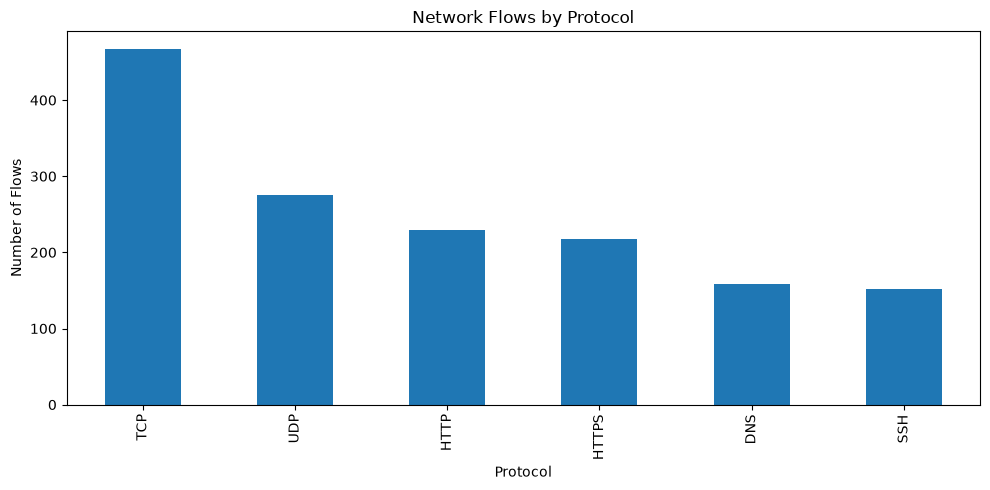

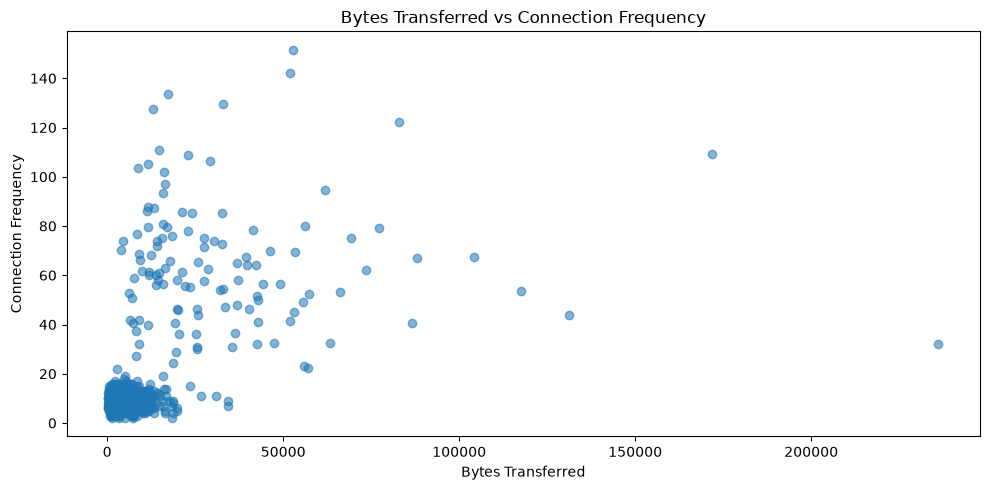

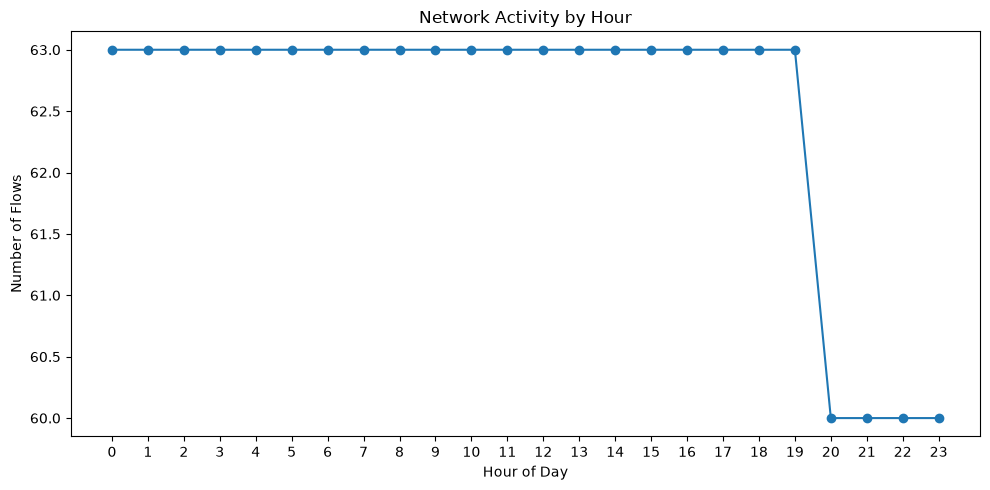

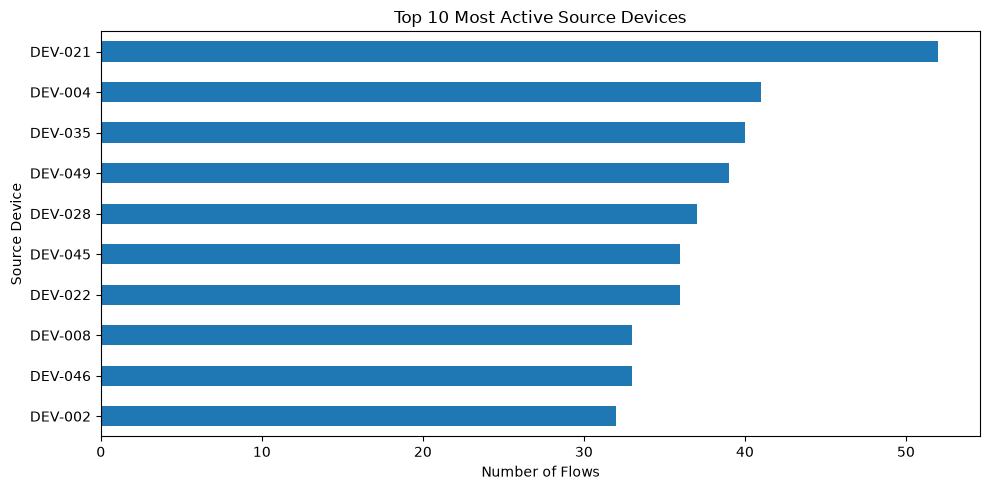

In [7]:
# 1. Protocol distribution
plt.figure(figsize=(10,5))
clean["Protocol"].value_counts().plot(kind="bar")
plt.title("Network Flows by Protocol")
plt.xlabel("Protocol")
plt.ylabel("Number of Flows")
plt.tight_layout()
plt.savefig(VIZ / "01_protocol_distribution.png", dpi=180)
plt.show()

# 2. Bytes vs connection frequency
plt.figure(figsize=(10,5))
plt.scatter(clean["Bytes_Transferred"], clean["Connection_Frequency"], alpha=0.55)
plt.title("Bytes Transferred vs Connection Frequency")
plt.xlabel("Bytes Transferred")
plt.ylabel("Connection Frequency")
plt.tight_layout()
plt.savefig(VIZ / "02_bytes_vs_frequency.png", dpi=180)
plt.show()

# 3. Hourly activity
plt.figure(figsize=(10,5))
hour_summary["Flows"].plot(kind="line", marker="o")
plt.title("Network Activity by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Flows")
plt.xticks(range(0,24))
plt.tight_layout()
plt.savefig(VIZ / "03_hourly_activity.png", dpi=180)
plt.show()

# 4. Top active devices
plt.figure(figsize=(10,5))
device_activity.head(10)["Flow_Count"].sort_values().plot(kind="barh")
plt.title("Top 10 Most Active Source Devices")
plt.xlabel("Number of Flows")
plt.ylabel("Source Device")
plt.tight_layout()
plt.savefig(VIZ / "04_top_active_devices.png", dpi=180)
plt.show()


## 7. KNN anomaly detection

In [8]:
X = clean[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k = 10
knn = NearestNeighbors(n_neighbors=k + 1)
knn.fit(X_scaled)

distances, indices = knn.kneighbors(X_scaled)

# Exclude the record itself from its neighbour-distance calculation.
clean["KNN_Anomaly_Score"] = distances[:, 1:].mean(axis=1)

# Flag the top 8% as unusual.
threshold = clean["KNN_Anomaly_Score"].quantile(0.92)
clean["KNN_Unusual"] = (clean["KNN_Anomaly_Score"] >= threshold).astype(int)

results = clean.sort_values("KNN_Anomaly_Score", ascending=False)
results.to_csv(RESULTS / "knn_anomaly_results.csv", index=False)

print("KNN:", k)
print("Anomaly threshold:", round(threshold, 4))
print("Unusual flows:", int(clean["KNN_Unusual"].sum()))
display(results.head(20)[[
    "Flow_ID","Timestamp","Source","Destination",
    "Bytes_Transferred","Duration","Protocol",
    "Connection_Frequency","KNN_Anomaly_Score","KNN_Unusual"
]])


KNN: 10
Anomaly threshold: 0.6941
Unusual flows: 120


,Flow_ID,Timestamp,Source,Destination,Bytes_Transferred,Duration,Protocol,Connection_Frequency,KNN_Anomaly_Score,KNN_Unusual
1285,F01286,2026-01-18 20:20:00,DEV-048,SRV-019,236158.75,4.75,HTTP,31.97,11.363894,1
884,F00885,2026-01-13 06:40:00,DEV-024,SRV-019,171850.14,24.58,HTTPS,109.35,7.317909,1
948,F00949,2026-01-14 04:00:00,DEV-006,SRV-019,52060.68,149.02,DNS,142.27,6.773995,1
954,F00955,2026-01-14 06:00:00,DEV-045,SRV-019,117601.03,77.67,UDP,53.81,5.409141,1
933,F00934,2026-01-13 23:00:00,DEV-028,SRV-019,11858.60,144.79,HTTP,61.25,5.062919,1
681,F00682,2026-01-10 11:00:00,DEV-007,SRV-019,131279.74,11.78,TCP,43.90,4.682038,1
910,F00911,2026-01-13 15:20:00,DEV-026,SRV-019,30344.48,141.29,HTTP,73.80,4.631721,1
463,F00464,2026-01-07 10:20:00,DEV-045,SRV-019,82929.25,37.89,HTTP,122.24,4.069094,1
1237,F01238,2026-01-18 04:20:00,DEV-048,SRV-019,52747.66,8.71,UDP,151.58,3.879160,1
1219,F01220,2026-01-17 22:20:00,DEV-025,SRV-019,19372.51,119.75,TCP,40.73,3.683256,1


## 8. Synthetic validation of the implementation

In [9]:
# This benchmark uses the synthetic validation truth created during dataset generation.
# It must NOT be described as real attack labels from the challenge.

eval_df = clean.merge(validation_truth, on="Flow_ID", how="inner")

y_true = eval_df["Validation_Unusual"]
y_pred = eval_df["KNN_Unusual"]

precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)
cm = confusion_matrix(y_true, y_pred)

print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1-score:  {f1:.3f}")
print("\nConfusion matrix:")
print(cm)


Precision: 0.942
Recall:    0.950
F1-score:  0.946

Confusion matrix:
[[1374    7]
 [   6  113]]


## 9. Key findings and action plan

In [10]:
protocol_anomaly = clean.groupby("Protocol")["KNN_Unusual"].mean().sort_values(ascending=False)
hour_anomaly = clean.groupby("Hour")["KNN_Unusual"].mean().sort_values(ascending=False)

print("KEY INSIGHTS")
print(f"1. {int(clean['KNN_Unusual'].sum())} of {len(clean)} cleaned flows were flagged as unusual.")
print(f"2. {protocol_anomaly.index[0]} had the highest unusual-flow rate in this synthetic dataset.")
print(f"3. {device_activity.index[0]} generated the highest number of flows.")
print(f"4. {device_activity['Total_Bytes'].idxmax()} generated the highest total transferred volume.")
print(f"5. Hour {int(hour_anomaly.index[0]):02d}:00 had the highest unusual-flow rate.")
print(f"6. The synthetic validation F1-score was {f1:.3f}.")
print("7. An anomaly is a deviation from the established baseline and should not automatically be labelled malicious.")

print("\nPRACTICAL ACTION PLAN")
actions = [
    "Prioritise high KNN-score flows for investigation.",
    "Review devices with repeated anomalous behaviour.",
    "Inspect unusually large transfers and high connection frequencies.",
    "Compare anomalies against normal protocol and hourly baselines.",
    "Investigate repeated source-destination pairs showing abnormal behaviour.",
    "Update the baseline periodically as network usage changes.",
    "Require contextual investigation before escalating an anomaly as a security incident."
]
for i, action in enumerate(actions, 1):
    print(f"{i}. {action}")


KEY INSIGHTS
1. 120 of 1500 cleaned flows were flagged as unusual.
2. HTTPS had the highest unusual-flow rate in this synthetic dataset.
3. DEV-021 generated the highest number of flows.
4. DEV-024 generated the highest total transferred volume.
5. Hour 23:00 had the highest unusual-flow rate.
6. The synthetic validation F1-score was 0.946.
7. An anomaly is a deviation from the established baseline and should not automatically be labelled malicious.

PRACTICAL ACTION PLAN
1. Prioritise high KNN-score flows for investigation.
2. Review devices with repeated anomalous behaviour.
3. Inspect unusually large transfers and high connection frequencies.
4. Compare anomalies against normal protocol and hourly baselines.
5. Investigate repeated source-destination pairs showing abnormal behaviour.
6. Update the baseline periodically as network usage changes.
7. Require contextual investigation before escalating an anomaly as a security incident.


## Conclusion

The project establishes a baseline for network behaviour using traffic volume, duration, connection frequency, protocol and time characteristics. KNN nearest-neighbour distances are used as an anomaly score to identify records that differ strongly from nearby behavioural patterns.

**Interpretation:** an unusual record is a candidate for investigation, not proof of malicious activity.
